# Calibration of the acceptance rule

Selection accepts a challenger when, on `V_select`, it has a median gain ≥ 5%, wins on ≥ 60% of the units and (with a corrector) actually corrects. That is a **protocol rule**, not a statistical test. The default thresholds and number of origins (`fold="auto"`, 7 when they fit) come from a calibration with a target fixed beforehand (ADR-0008): false acceptance ≤ 10% and useful gains accepted ≥ 50%. This notebook repeats that measurement on a smaller scale, comparing the previous rule (gain ≥ 1%), the default one and the default one with a Wilcoxon test, on two controls whose right answer is known:

| Control | Series | Right answer | Error measured |
|---|---|---|---|
| `white_noise` (negative) | level + white noise | keep a standalone model | **false acceptance**: hybrid champion |
| `ar_residual` (positive) | trend + seasonality + AR(0.8) noise, bases without AR | accept the hybrid | **rejected useful gain**: standalone champion |

For each series and number of origins in `V_select` (`fold`), the search and the selection run once; each policy is applied to the **same** finalists. The rates resample **series** (origins of one series are not independent). The sealed test is never read.

Two sets with disjoint seeds: **calibration** (to look at and decide) and **confirmation** (to check once).

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

import autohybts
from autohybts.benchmarks.calibration import (
    calibration_protocol,
    calibration_report,
    control_cases,
    run_calibration,
)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Configuration

In [2]:
N_SERIES = 20  # per control (the full calibration used 50)
FOLDS = (3, 7)  # previous default and calibrated
POLICIES = {
    "previous (gain ≥ 1%)": {"median_gain_threshold": 0.01},
    "default (gain ≥ 5%)": {},
    "default + Wilcoxon 0.05": {"significance_alpha": 0.05},
}

protocol = calibration_protocol(N_SERIES, "calibration", FOLDS, POLICIES)
print(
    "default thresholds:",
    {k: protocol["base_policy"][k] for k in ("median_gain_threshold", "win_rate_threshold")},
)
print("variability:", protocol["base_policy"]["variability"])
print("budget:", protocol["budget"], "| horizon:", protocol["fh"])

default thresholds: {'median_gain_threshold': 0.05, 'win_rate_threshold': 0.6}
variability: {'name': 'correction_std_ratio', 'version': 2, 'threshold': 0.05, 'direction': 'gte', 'aggregation': 'median'}
budget: smoke | horizon: 7


## 2. Calibration set

`hybrid_champion_rate` is the fraction of series with a hybrid champion. In the negative control it is the **false acceptance rate per chain**; in the positive one, `rejected_gain_rate = 1 − rate`. `min_one_sided_p` is the smallest p-value Wilcoxon can give with that number of units. In the figure, the dashed line is the target: false acceptance ≤ 10% on white noise and useful gains accepted ≥ 50% on the AR residual.

In [3]:
started = time.perf_counter()
table = run_calibration(control_cases(N_SERIES, "calibration"), FOLDS, POLICIES)
print(f"{len(table)} rows in {(time.perf_counter() - started) / 60:.1f} min")
report = calibration_report(table)
columns = [
    "kind",
    "select_units",
    "min_one_sided_p",
    "hybrid_champion_rate",
    "rate_ci_low",
    "rate_ci_high",
    "rejected_gain_rate",
]
report[columns].round(3)

240 rows in 2.7 min


kind  select_units  min_one_sided_p  hybrid_champion_rate  rate_ci_low  rate_ci_high  rejected_gain_rate
control     fold policy                                                                                                                               
ar_residual 3    default (gain ≥ 5%)      positive             3            0.125                  0.55         0.35          0.80                0.45
                 default + Wilcoxon 0.05  positive             3            0.125                  0.00         0.00          0.00                1.00
                 previous (gain ≥ 1%)     positive             3            0.125                  0.65         0.45          0.85                0.35
            7    default (gain ≥ 5%)      positive             7            0.008                  0.70         0.50          0.90                0.30
                 default + Wilcoxon 0.05  positive             7            0.008                  0.10         0.00          0.25                0.90
                 previous (gain ≥ 1%)     positive             7            0.008                  0.70         0.50          0.90                0.30
white_noise 3    default (gain ≥ 5%)      negative             3            0.125                  0.10         0.00          0.25                 NaN
                 default + Wilcoxon 0.05  negative             3            0.125                  0.00         0.00          0.00                 NaN
                 previous (gain ≥ 1%)     negative             3            0.125                  0.40         0.20          0.60                 NaN
            7    default (gain ≥ 5%)      negative             7            0.008                  0.00         0.00          0.00                 NaN
                 default + Wilcoxon 0.05  negative             7            0.008                  0.00         0.00          0.00                 NaN
                 previous (gain ≥ 1%)     negative             7            0.008                  0.05         0.00          0.15                 NaN

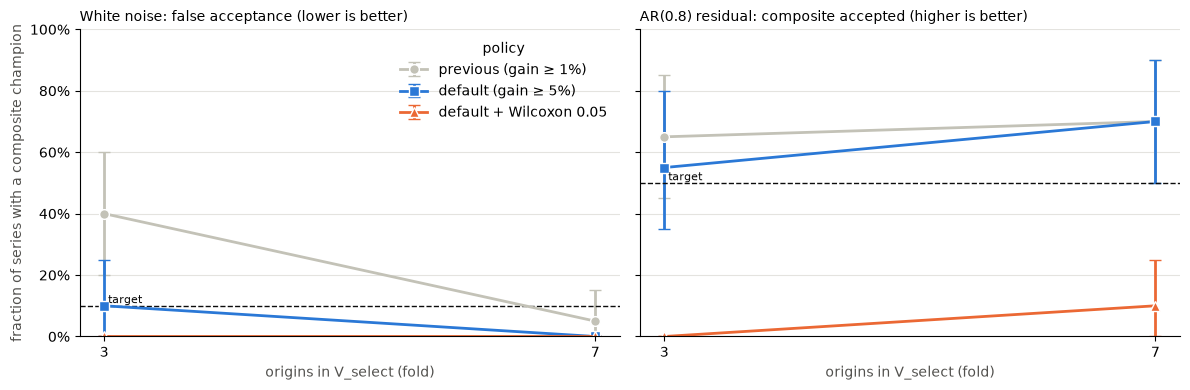

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
titles = {
    "white_noise": "White noise: false acceptance (lower is better)",
    "ar_residual": "AR(0.8) residual: composite accepted (higher is better)",
}
colors = ["#c3c2b7", "#2a78d6", "#eb6834"]  # one fixed colour per policy
for ax, control in zip(axes, ["white_noise", "ar_residual"], strict=True):
    part = report.loc[control]
    for policy, marker, color in zip(POLICIES, ["o", "s", "^"], colors, strict=True):
        rows = part.xs(policy, level="policy")
        ax.errorbar(
            rows.index,
            rows["hybrid_champion_rate"],
            yerr=[
                rows["hybrid_champion_rate"] - rows["rate_ci_low"],
                rows["rate_ci_high"] - rows["hybrid_champion_rate"],
            ],
            marker=marker,
            markersize=7,
            markeredgecolor="white",
            color=color,
            linewidth=2,
            capsize=4,
            label=policy,
        )
    target = 0.10 if control == "white_noise" else 0.50  # ADR-0008 targets
    ax.axhline(target, color="#0b0b0b", linewidth=1, linestyle="--")
    ax.text(FOLDS[0], target, " target", va="bottom", fontsize=8, color="#0b0b0b")
    ax.set_title(titles[control], loc="left", fontsize=10)
    ax.set_xlabel("origins in V_select (fold)", color="#52514e")
    ax.set_xticks(list(FOLDS))
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("fraction of series with a composite champion", color="#52514e")
axes[0].legend(frameon=False, title="policy")
fig.tight_layout()

## 3. Confirmation set

Same conditions, other series. If a policy were chosen by looking at the calibration, this would be the single check.

In [5]:
confirmation = calibration_report(
    run_calibration(control_cases(N_SERIES, "confirmation"), FOLDS, POLICIES)
)
side_by_side = pd.concat(
    {
        "calibration": report["hybrid_champion_rate"],
        "confirmation": confirmation["hybrid_champion_rate"],
    },
    axis=1,
)
side_by_side.round(3)

calibration  confirmation
control     fold policy                                            
ar_residual 3    default (gain ≥ 5%)             0.55          0.45
                 default + Wilcoxon 0.05         0.00          0.00
                 previous (gain ≥ 1%)            0.65          0.55
            7    default (gain ≥ 5%)             0.70          0.60
                 default + Wilcoxon 0.05         0.10          0.25
                 previous (gain ≥ 1%)            0.70          0.60
white_noise 3    default (gain ≥ 5%)             0.10          0.05
                 default + Wilcoxon 0.05         0.00          0.00
                 previous (gain ≥ 1%)            0.40          0.25
            7    default (gain ≥ 5%)             0.00          0.00
                 default + Wilcoxon 0.05         0.00          0.00
                 previous (gain ≥ 1%)            0.05          0.00

## 4. Reading the results

In this run (20 series per control and set, `fh=7`, `smoke` budget; the full ADR-0008 calibration used 50):

* **With 3 origins, the gain threshold makes the biggest difference.** On white noise, the previous rule (gain ≥ 1%) lets a hybrid become champion in 40% of the calibration series (25% on confirmation); the default one (≥ 5%), in 10% (5%). The cost is small on the AR residual: useful gains accepted drop from 65% to 55% (55% to 45% on confirmation).
* **With 7 origins, the default rule meets the target on both sets:** no false acceptance on white noise and 70% (calibration) and 60% (confirmation) of useful gains accepted. With 7 units even the previous rule hardly accepts spurious structures here (5% and 0%): the number of origins weighs as much as the threshold.
* **Wilcoxon still trades one error for the other:** it removes false acceptances but accepts only 0–25% of useful gains, even with 7 units.
* **Confirmation stays in the calibration's range**, always somewhat lower on the AR residual. With 20 series the 95% intervals span ±20 points: take these numbers as an illustration; the decision rests on the 50-series measurement (ADR-0008, selection guide).

That is why the default is gain ≥ 5% with `fold="auto"` (7 origins when the series allows). On short series, which allow fewer origins, the rule falls between the 3 and 7 rows of this table, and the experiment warns. Limits: two daily synthetic controls, one hybrid comparison per chain, one budget and one session seed.